In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             confusion_matrix, classification_report, accuracy_score)

import statsmodels.api as sm

# Importaciones para Apriori
from collections import Counter
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import networkx as nx
from IPython.display import display

import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)


In [28]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:
ruta_archivo = '/content/drive/MyDrive/mineria/'
df = pd.read_csv(f'{ruta_archivo}online_shoppers_intention.csv')
df


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [31]:
# Verificar que no tenga valores nulos
df.isna().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [32]:
# encontrar duplicados
print("Regirstros duplicados : ", df.duplicated().sum())
df[df.duplicated(keep=False)]

Regirstros duplicados :  125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11934,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,2,New_Visitor,False,False
11938,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,4,1,Returning_Visitor,True,False
12159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,3,Returning_Visitor,False,False
12180,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,13,9,20,Returning_Visitor,False,False


In [33]:
df_original = df.copy()

In [34]:
# elininar regristros duplicados
renglones_antes = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)
renglones_despues = len(df)
print(f"Rengloness antes: {renglones_antes}")
print(f"Rengloness despues: {renglones_despues}")
print(f"Rengloness eliminados: {renglones_antes - renglones_despues}")

Rengloness antes: 12330
Rengloness despues: 12205
Rengloness eliminados: 125


## **Análisis exploratorio de datos y preprocesamiento de datos**
Separar variables numéricas y categóricas

# Descripcion de variables

| Variable | Descripción |
|---|---|
| `Administrative` | Número de páginas administrativas visitadas. |
| `Administrative_Duration` | Tiempo en páginas administrativas, en segundos. |
| `Informational` | Número de páginas informativas visitadas. |
| `Informational_Duration` | Tiempo en páginas informativas, en segundos. |
| `ProductRelated` | Número de páginas de productos visitadas. |
| `ProductRelated_Duration` | Tiempo en páginas de productos, en segundos. |
| `BounceRates` | Tasa de rebote. |
| `ExitRates` | Tasa de salida. |
| `PageValues` | Valor promedio atribuido a páginas visitadas antes de una transacción. |
| `SpecialDay` | Proximidad a un día comercial especial, entre 0 y 1. |
| `Month` | Mes de la sesión. |
| `OperatingSystems` | Código del sistema operativo. |
| `Browser` | Código del navegador. |
| `Region` | Código de la región. |
| `TrafficType` | Código del tipo de tráfico. |
| `VisitorType` | Tipo de visitante. |
| `Weekend` | Indica si la sesión ocurrió en fin de semana. |
| `Revenue` | Variable objetivo: indica si la sesión terminó en compra. |


In [41]:
# hacemos SpecialDay un valor categorico ordinal
df['SpecialDay'] = pd.Categorical(
    df['SpecialDay'],
    categories=[0,0.2,0.4,0.6,0.8,1],
    ordered=True
)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Administrative           12205 non-null  int64   
 1   Administrative_Duration  12205 non-null  float64 
 2   Informational            12205 non-null  int64   
 3   Informational_Duration   12205 non-null  float64 
 4   ProductRelated           12205 non-null  int64   
 5   ProductRelated_Duration  12205 non-null  float64 
 6   BounceRates              12205 non-null  float64 
 7   ExitRates                12205 non-null  float64 
 8   PageValues               12205 non-null  float64 
 9   SpecialDay               12205 non-null  category
 10  Month                    12205 non-null  object  
 11  OperatingSystems         12205 non-null  int64   
 12  Browser                  12205 non-null  int64   
 13  Region                   12205 non-null  int64   
 14  Traffi

In [42]:
# Verificamos su cambio
df['SpecialDay'].dtype

CategoricalDtype(categories=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0], ordered=True, categories_dtype=float64)

In [35]:
variables_numericas = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration','ProductRelated', 'ProductRelated_Duration','BounceRates','ExitRates',
                       'PageValues']
variables_categoricas = ['Month', 'OperatingSystems','Browser', 'Region','TrafficType','VisitorType','Weekend', 'Revenue','SpecialDay']

In [36]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,2.124211,2.357804,3.153298,4.073904
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,0.906823,1.710114,2.402340,4.016654
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [37]:
df[variables_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.338878,3.330436,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12205.0,81.646331,177.491845,0.0,0.000000,9.000000,94.700000,3398.750000
Informational,12205.0,0.508726,1.275617,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12205.0,34.825454,141.424807,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12205.0,32.045637,44.593649,0.0,8.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12205.0,1206.982457,1919.601400,0.0,193.000000,608.942857,1477.154762,63973.522230
BounceRates,12205.0,0.020370,0.045255,0.0,0.000000,0.002899,0.016667,0.200000
ExitRates,12205.0,0.041466,0.046163,0.0,0.014231,0.025000,0.048529,0.200000
PageValues,12205.0,5.949574,18.653671,0.0,0.000000,0.000000,0.000000,361.763742


### Observaciones de las variables numericas

- En **`ProductRelated_Duration`** podemos observar que el promedio de que una persona revisa cada pagina relacionadas a productos es de aproxiamdamente 2 minutos
- En  **`BounceRates** nos vemos que en la escala que se tiene en este campo en promedio un 0.2 de los usuarios se salen sin ver otra pagina

In [38]:
df[variables_categoricas].describe(include='all')

,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,SpecialDay
count,12205,12205.000000,12205.000000,12205.000000,12205.000000,12205,12205,12205,12205.000000
unique,10,NaN,NaN,NaN,NaN,3,2,2,NaN
top,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False,NaN
freq,3329,NaN,NaN,NaN,NaN,10431,9346,10297,NaN
mean,NaN,2.124211,2.357804,3.153298,4.073904,NaN,NaN,NaN,0.061942
std,NaN,0.906823,1.710114,2.402340,4.016654,NaN,NaN,NaN,0.199666
min,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN,0.000000
25%,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN,0.000000
50%,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN,0.000000
75%,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN,0.000000


### Observaciones de las variables categoricas

- En **`SpecialDay`** podemos observar que aun al 75% de las seciones no estuvieron ni cerca de estar de un dia especial(celebre)

In [56]:
# Identificar valores unicos
# unique regresa valores unicos ,como el distinct en sql
for v in variables_categoricas:
  print(f"Valores unicos de {v}")
  print(df[v].unique())

Valores unicos de Month
['Feb' 'Mar' 'May' 'Oct' 'June' 'Jul' 'Aug' 'Nov' 'Sep' 'Dec']
Valores unicos de OperatingSystems
[1 2 4 3 7 6 8 5]
Valores unicos de Browser
[ 1  2  3  4  5  6  7 10  8  9 12 13 11]
Valores unicos de Region
[1 9 2 3 4 5 6 7 8]
Valores unicos de TrafficType
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 18 19 16 17 20]
Valores unicos de VisitorType
['Returning_Visitor' 'New_Visitor' 'Other']
Valores unicos de Weekend
[False  True]
Valores unicos de Revenue
[False  True]
Valores unicos de SpecialDay
[0.0, 0.4, 0.8, 1.0, 0.2, 0.6]
Categories (6, float64): [0.0 < 0.2 < 0.4 < 0.6 < 0.8 < 1.0]


In [40]:
# Identificar valores unicos
for v in variables_categoricas:
  print("------------------------")
  print(df[v].value_counts())

------------------------
Month
May     3329
Nov     2982
Mar     1860
Dec     1706
Oct      549
Sep      448
Aug      433
Jul      432
June     285
Feb      181
Name: count, dtype: int64
------------------------
OperatingSystems
2    6541
1    2549
3    2530
4     478
8      75
6      19
7       7
5       6
Name: count, dtype: int64
------------------------
Browser
2     7883
1     2427
4      731
5      465
6      174
10     163
8      135
3      105
13      56
7       49
12      10
11       6
9        1
Name: count, dtype: int64
------------------------
Region
1    4714
3    2379
4    1171
2    1128
6     801
7     758
9     505
8     431
5     318
Name: count, dtype: int64
------------------------
TrafficType
2     3911
1     2388
3     2013
4     1066
13     728
10     450
6      443
8      343
5      260
11     247
20     193
9       41
7       40
15      37
19      17
14      13
18      10
16       3
12       1
17       1
Name: count, dtype: int64
------------------------
Visitor

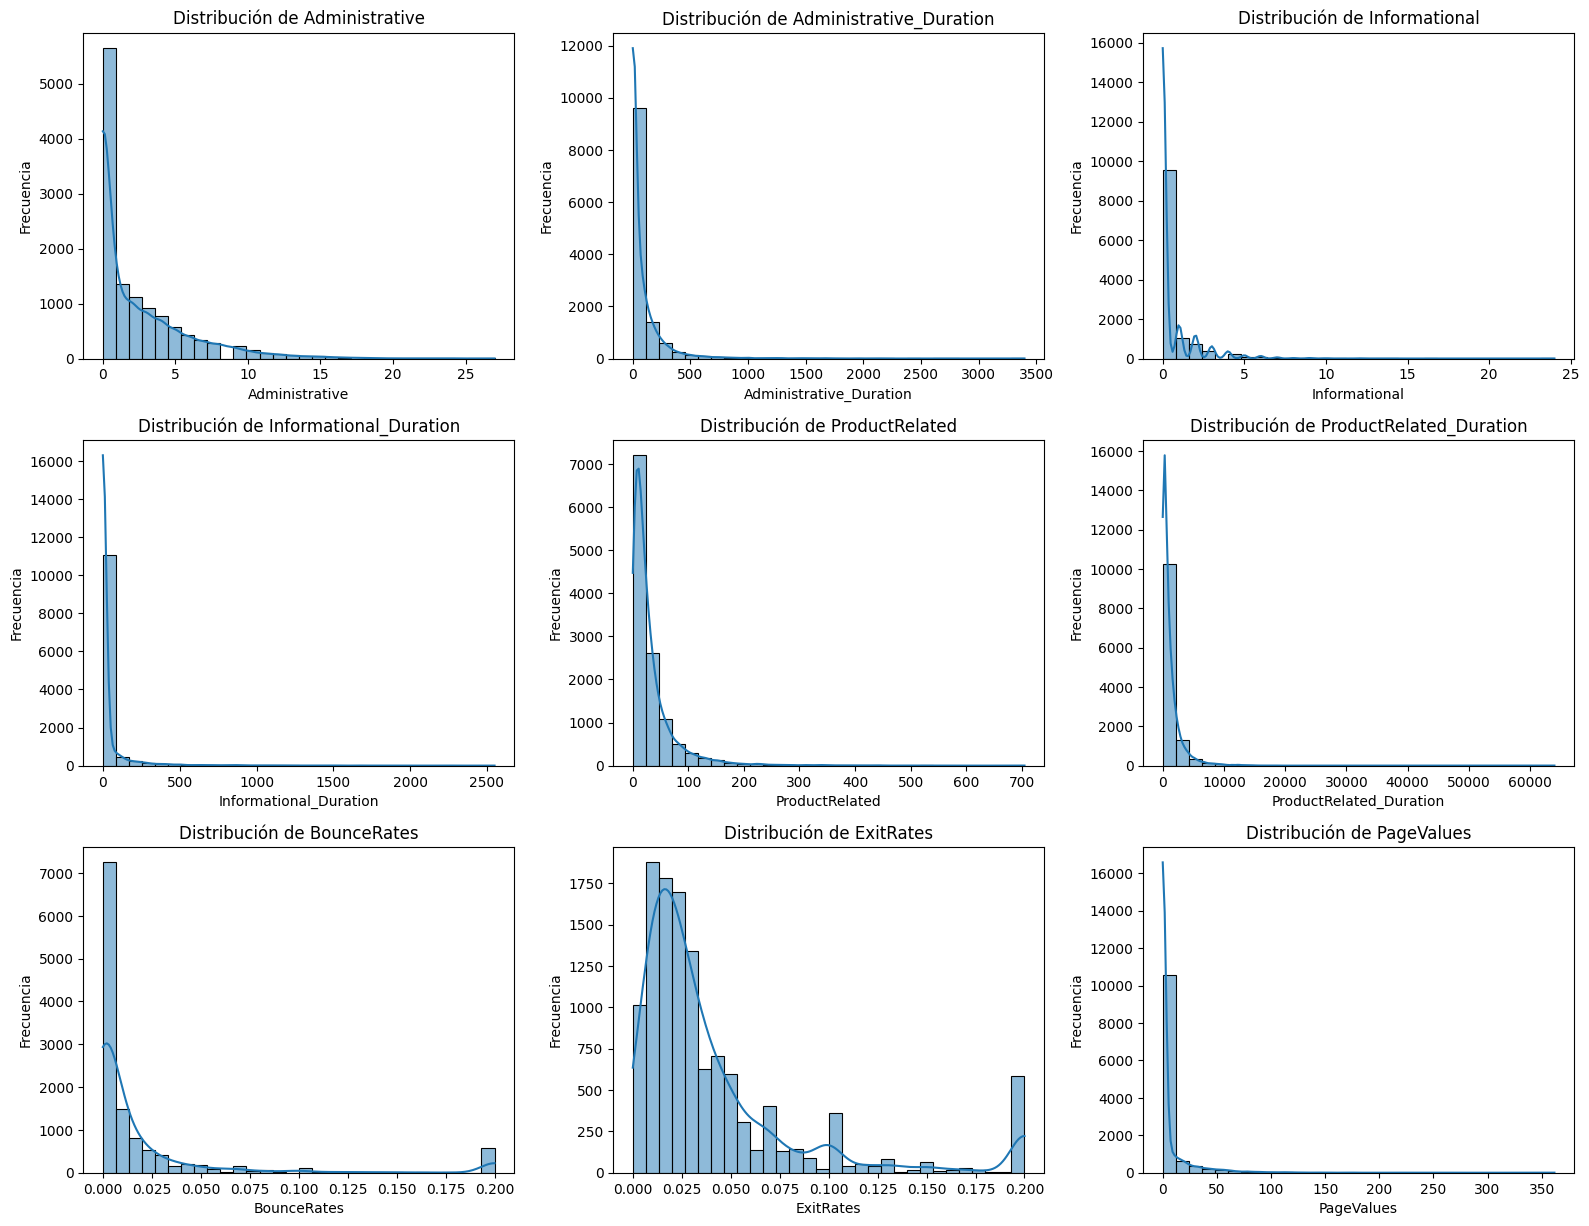

In [44]:
# Histogramas de varibles niumericas con distribucion
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.flatten()

for i, v in enumerate(variables_numericas):
    sns.histplot(df[v], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribución de {v}')
    axes[i].set_xlabel(v)
    axes[i].set_ylabel('Frecuencia')

for j in range(len(variables_numericas), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

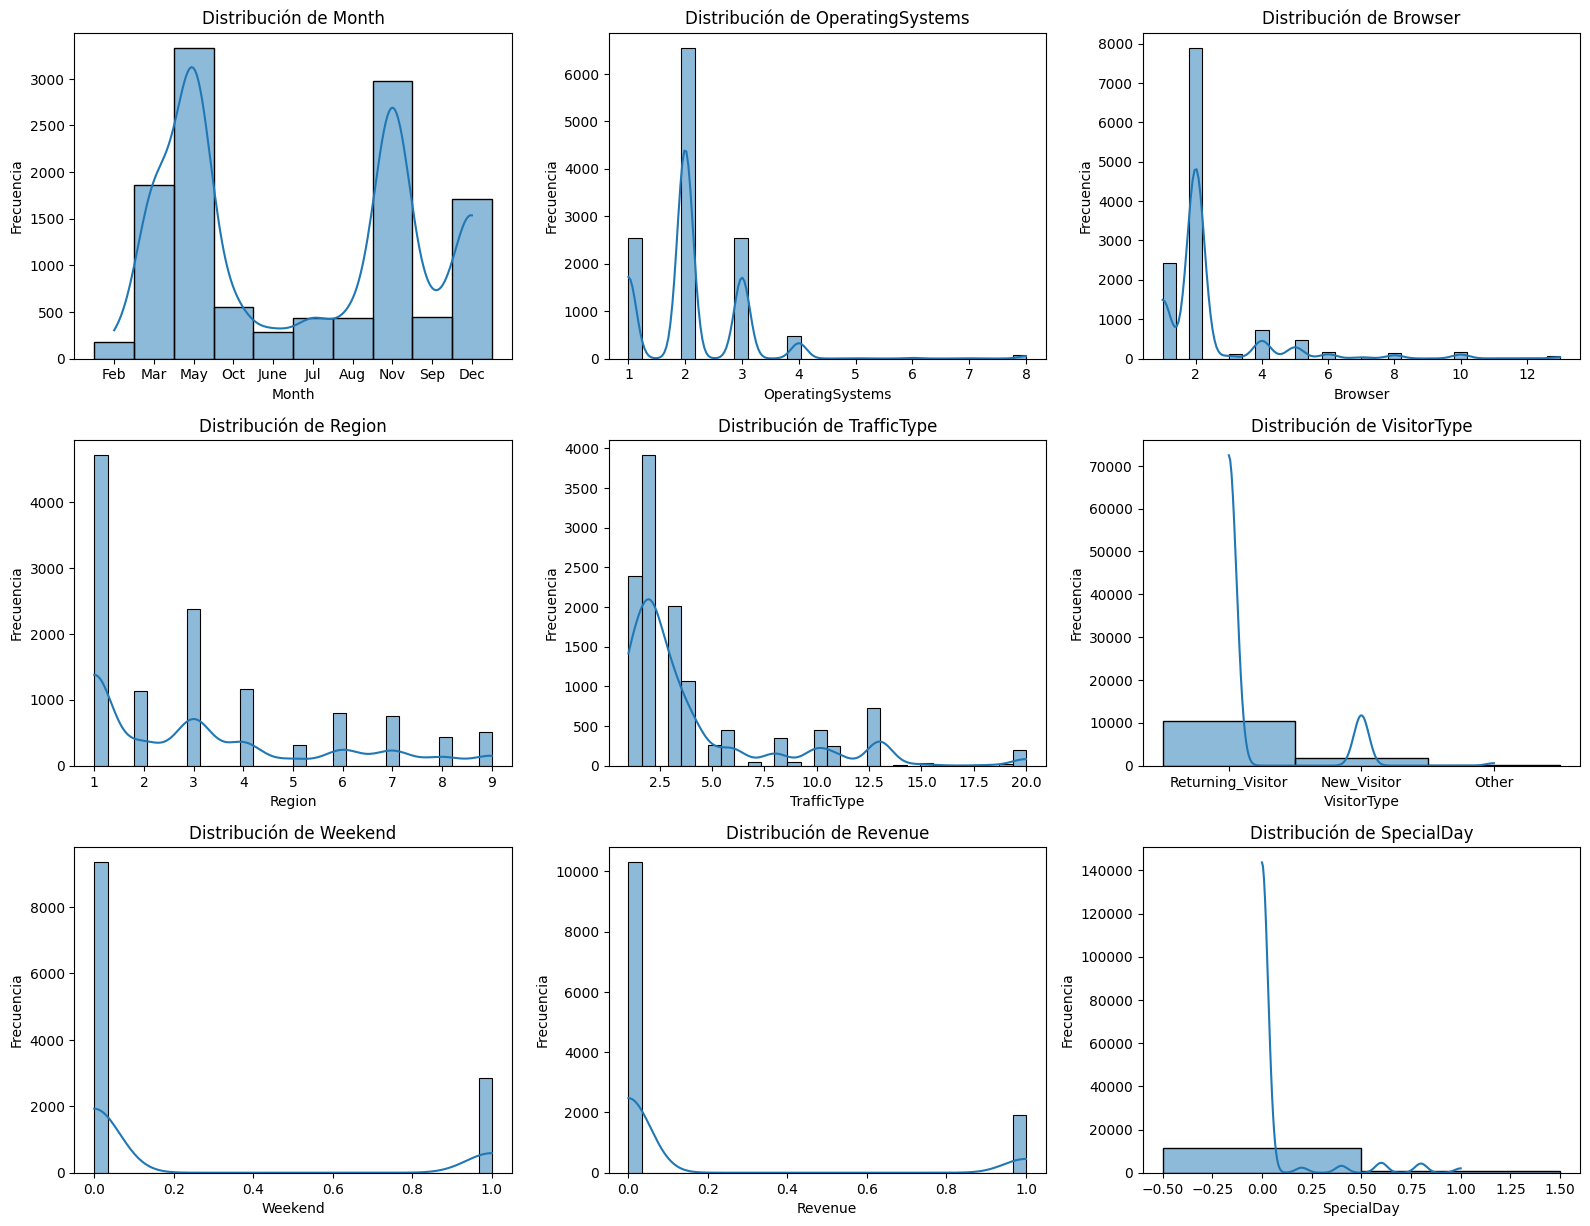

In [45]:
# Histogramas de varibles categoricas con distribucion
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.flatten()

for i, v in enumerate(variables_categoricas):
    sns.histplot(df[v], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribución de {v}')
    axes[i].set_xlabel(v)
    axes[i].set_ylabel('Frecuencia')

for j in range(len(variables_categoricas), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


- Podemos ver que en los meses de mayo y noviembre se tiene una mayor cantidad de usuarios
- La mayoria de usuarios estan en la primer region con una enorme diferencia, le sigue la region 3
- La mayoria de usuarios son usuarios son recurrentes
- Muy pocas sesiones terminan con una compra

In [46]:
# Imprimir el % de valores por cada categoria
for i in variables_categoricas:
    print(f'porcentaje de valores en {i}')
    print(df[i].value_counts(normalize=True))
    print(df[i].value_counts())
    print('*'*40)

porcentaje de valores en Month
Month
May     0.272757
Nov     0.244326
Mar     0.152397
Dec     0.139779
Oct     0.044982
Sep     0.036706
Aug     0.035477
Jul     0.035395
June    0.023351
Feb     0.014830
Name: proportion, dtype: float64
Month
May     3329
Nov     2982
Mar     1860
Dec     1706
Oct      549
Sep      448
Aug      433
Jul      432
June     285
Feb      181
Name: count, dtype: int64
****************************************
porcentaje de valores en OperatingSystems
OperatingSystems
2    0.535928
1    0.208849
3    0.207292
4    0.039164
8    0.006145
6    0.001557
7    0.000574
5    0.000492
Name: proportion, dtype: float64
OperatingSystems
2    6541
1    2549
3    2530
4     478
8      75
6      19
7       7
5       6
Name: count, dtype: int64
****************************************
porcentaje de valores en Browser
Browser
2     0.645883
1     0.198853
4     0.059893
5     0.038099
6     0.014256
10    0.013355
8     0.011061
3     0.008603
13    0.004588
7     0.00401

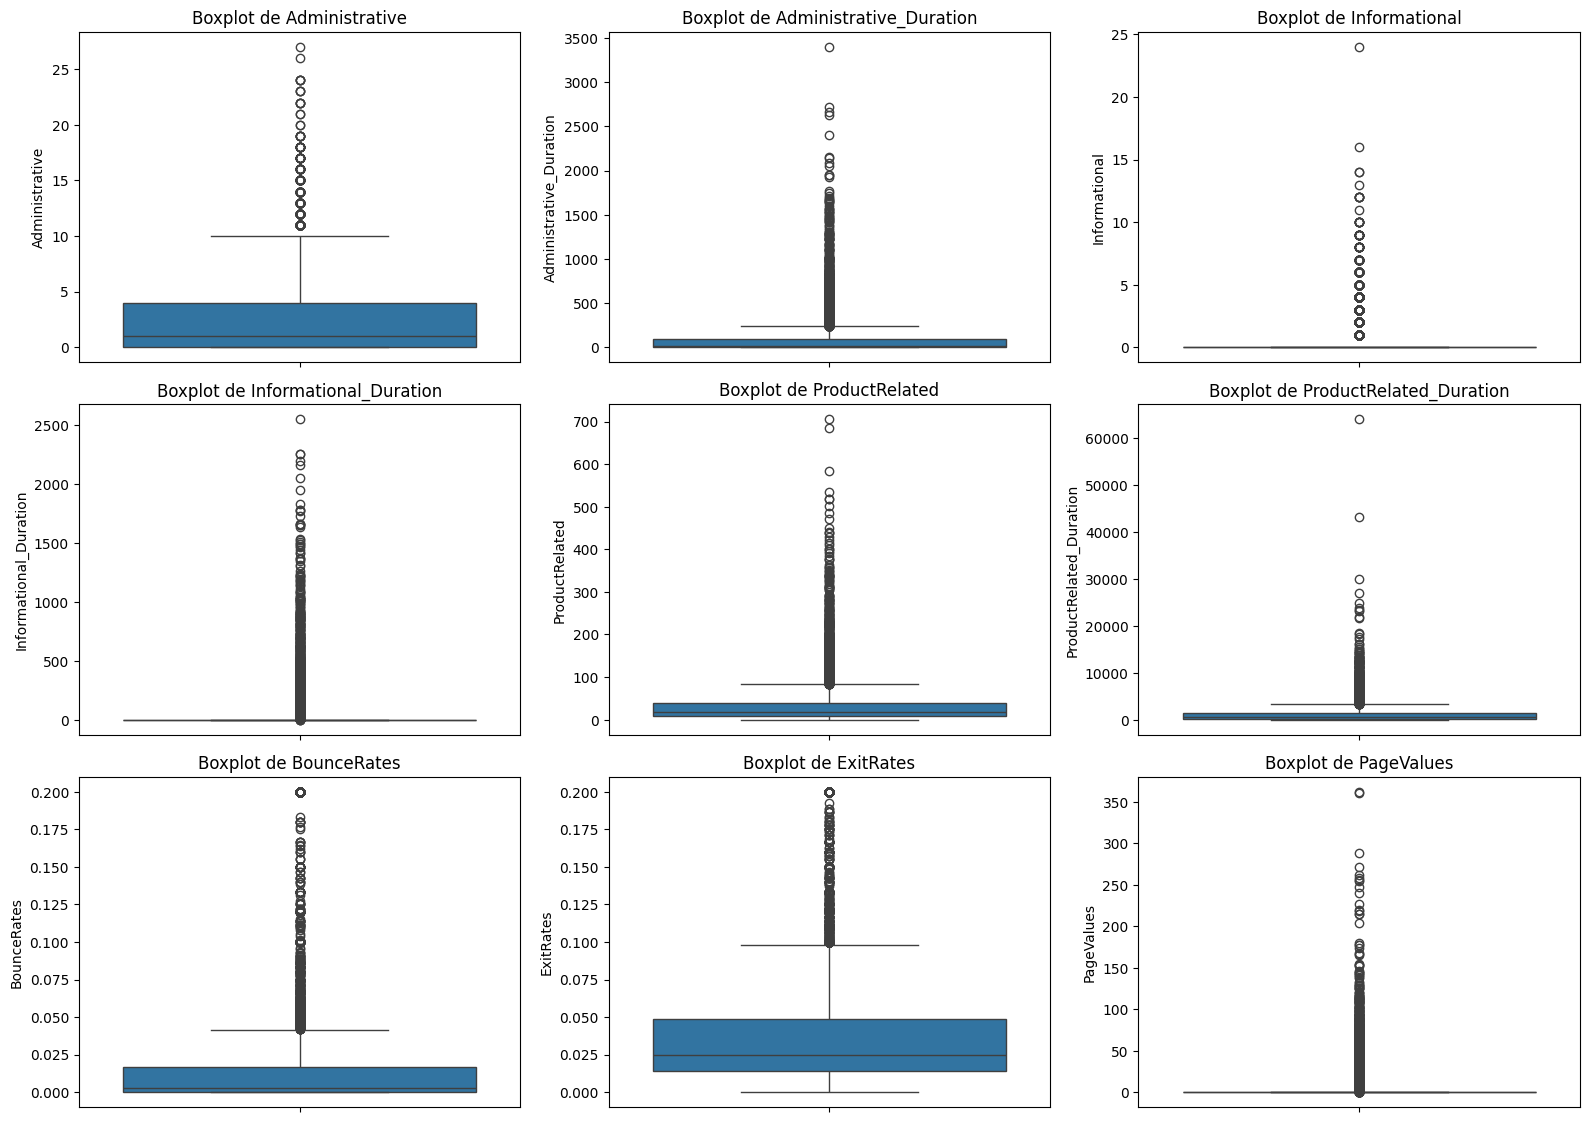

In [61]:
fig, axes = plt.subplots(4, 3, figsize=(16, 15))
axes = axes.flatten()

for i, v in enumerate(variables_numericas):
    sns.boxplot(data=df, y=v, ax=axes[i])
    axes[i].set_title(f'Boxplot de {v}')

for j in range(len(variables_numericas), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Observaciones**

- Todas de variables numericas presentan una gran cantidad de datos atipicos superiores
- En **`ProductRelated`** y **`ProductRelated_Duration`**, se observan máximos de **705 páginas** y **63,973.52 segundos**, respectivamente.
- **`BounceRates`** y **`ExitRates`** presentan puntos por encima del bigote superior. En ambos casos, el máximo observado es de **0.20**.
- En **`Informational`**, **`Informational_Duration`**, y **`PageValues`** el primer y el tercer cuartil son cero. Por eso la caja se reduce a una línea y la regla del rango intercuartílico señala los valores

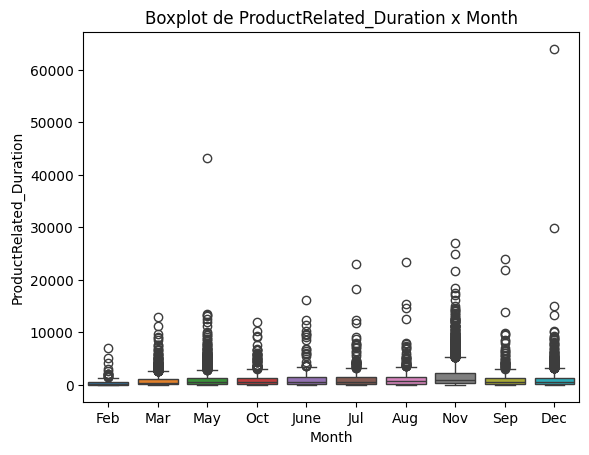

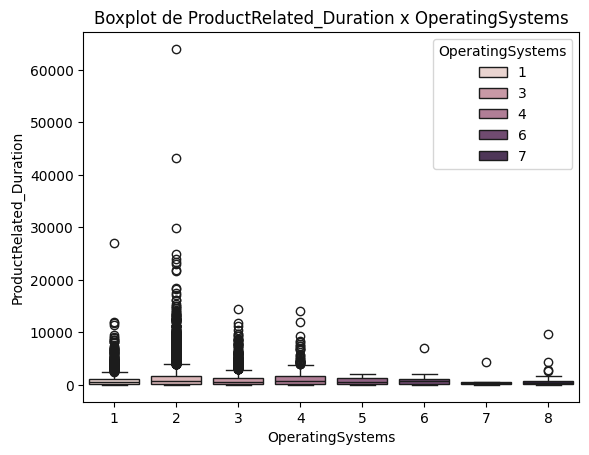

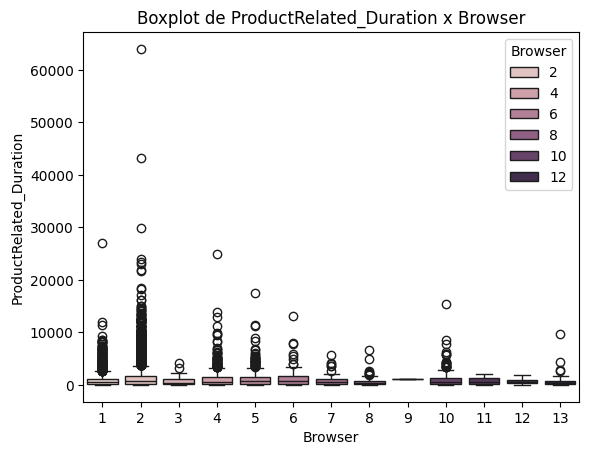

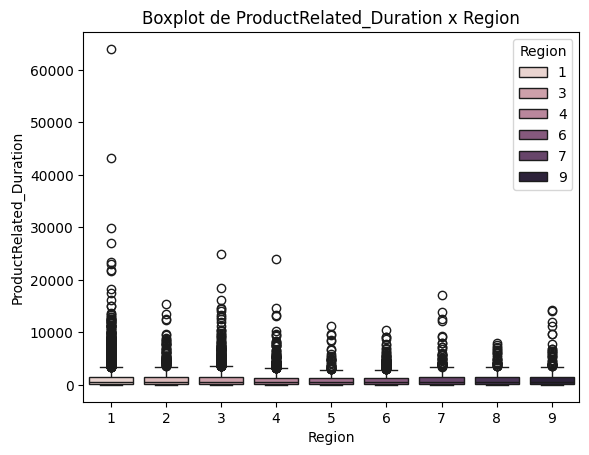

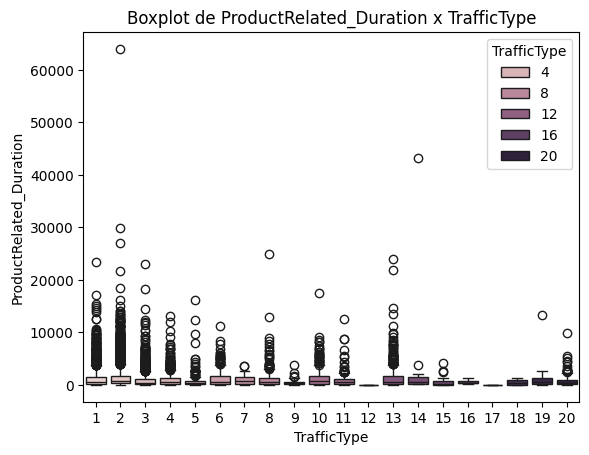

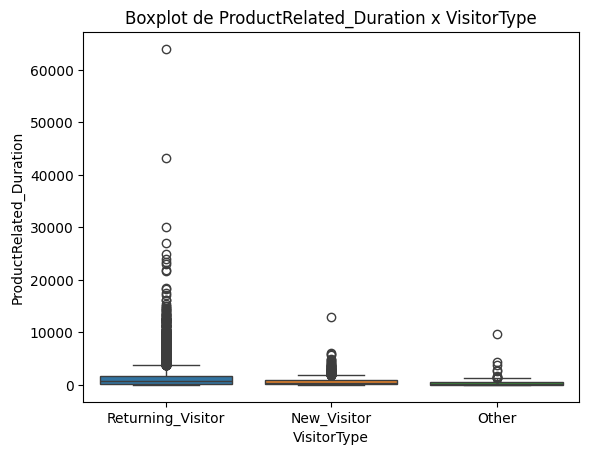

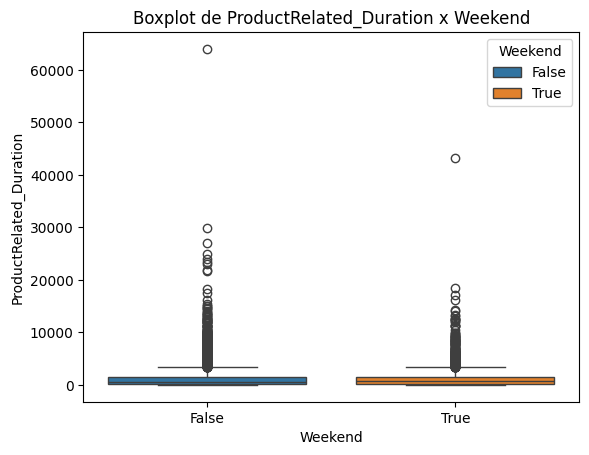

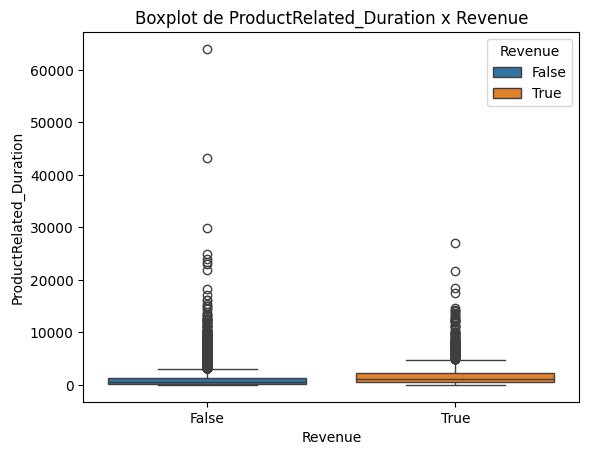

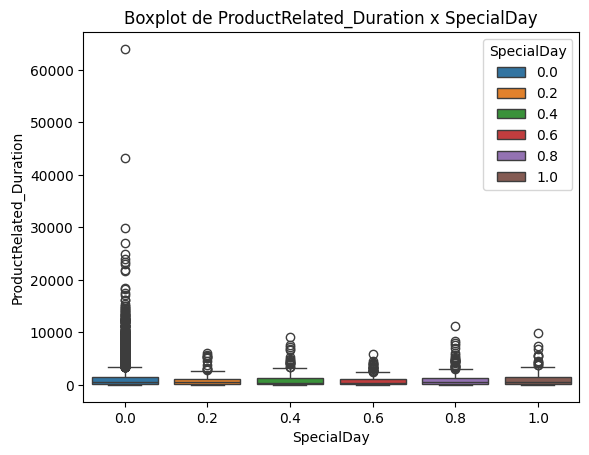

In [75]:
for v in variables_categoricas:
    sns.boxplot(data=df, y='ProductRelated_Duration', x=v, hue=v)
    plt.title(f'Boxplot de ProductRelated_Duration x {v}')
    plt.ylabel(v)
    plt.ylabel("ProductRelated_Duration")
    plt.show()

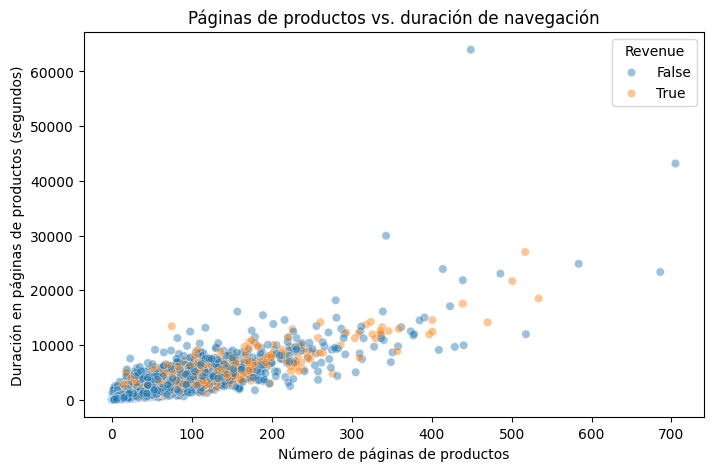

In [74]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='ProductRelated',
    y='ProductRelated_Duration',
    hue='Revenue',
    alpha=0.45
)
plt.title('Páginas de productos vs. duración de navegación')
plt.xlabel('Número de páginas de productos')
plt.ylabel('Duración en páginas de productos (segundos)')
plt.show()

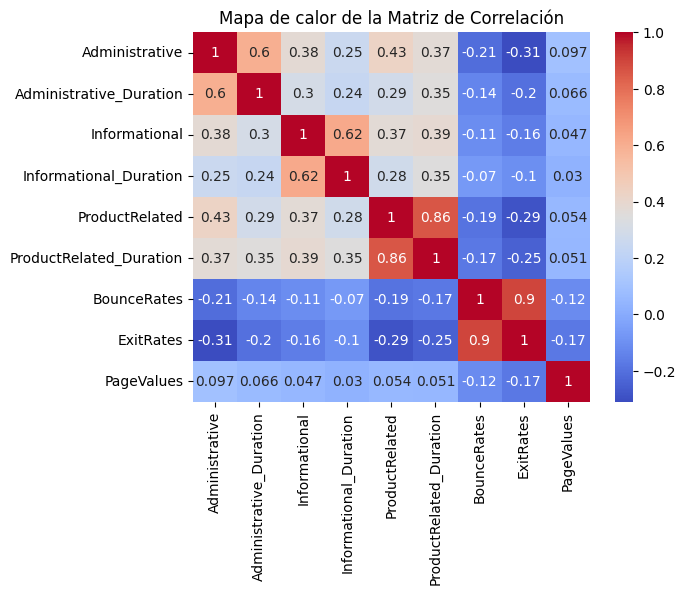

### Análisis de Correlaciones
**Observaciones**

- Tasa de rebote y tasa de salida: `BounceRates` y `ExitRates`, r = 0.9. Es la correlación más alta entre dos variables distintas. Las sesiones con una tasa de rebote más alta tienden a registrar también una tasa de salida más alta.

- Páginas de productos y tiempo de navegación: `ProductRelated` y `ProductRelated_Duration`, r = 0.86. Las sesiones en las que se consultaron más páginas de productos tendieron a registrar más tiempo en esa sección. También se observa esta tendencia en las páginas informativas **(r = 0.62)** y administrativas **(r = 0.60)**, aunque la relación es menos fuerte.

- Tasa de salida y páginas administrativas: `ExitRates` y `Administrative`, r = −0.31. Es la correlación negativa de mayor magnitud en el mapa. Las sesiones con una tasa de salida más alta tendieron a registrar menos páginas administrativas, aunque la relación es más débil que la observada entre las tasas de rebote y salida.

- PageValues es la variable que menos relacion tiene con las demas y todas las relaciones se inclinan por casi nada a una correlacion negativa, pero es tan pequeña que es insignificante

In [60]:
# Comparación de variables categóricas con Revenue ordenadas con mayor porcentaje de compra
for v in variables_categoricas:
    print(f"\nPorcentaje de Revenue según {v}:")
    tabla = pd.crosstab(df[v], df['Revenue'], normalize='index') * 100
    tabla_ordenada = tabla.sort_values(by=True, ascending=False)
    display(tabla_ordenada.round(2))


Porcentaje de Revenue según Month:


Revenue,False,True
Month,,
Nov,74.51,25.49
Oct,79.05,20.95
Sep,80.80,19.20
Aug,82.45,17.55
Jul,84.72,15.28
Dec,87.34,12.66
May,89.04,10.96
Mar,89.68,10.32
June,89.82,10.18



Porcentaje de Revenue según OperatingSystems:


Revenue,False,True
OperatingSystems,,
8,77.33,22.67
4,82.22,17.78
2,82.34,17.66
5,83.33,16.67
1,85.13,14.87
7,85.71,14.29
3,89.41,10.59
6,89.47,10.53



Porcentaje de Revenue según Browser:


Revenue,False,True
Browser,,
12,70.00,30.00
13,71.43,28.57
10,80.37,19.63
5,81.51,18.49
4,82.22,17.78
11,83.33,16.67
8,84.44,15.56
2,84.49,15.51
1,84.96,15.04


... (8 outputs left out)


Porcentaje de Revenue según Revenue:


Revenue,False,True
Revenue,,
True,0.0,100.0
False,100.0,0.0



Porcentaje de Revenue según SpecialDay:


Revenue,False,True
SpecialDay,,
0.0,83.29,16.71
0.6,91.71,8.29
0.2,92.13,7.87
1.0,93.51,6.49
0.4,94.65,5.35
0.8,96.60,3.40


### Análisis de comparacion con revenue

- Se observa que los meses con mayor porcentaje de cantidad de usuarios que visitaron la pagina y terminaron comprando son noviembre, octubre y septiembre

- Se observa que las regiones con mayor porcentaje de cantidad de usuarios que visitaron la pagina y terminaron comprando son 9,2 y 1

- Podemos ver que los nuevos usuarios son los que terminan optando por comprar mas proporcionalmente

- Se aprecia que los usuarios que visitan la pagina en fin de semana terminan comprando en porcentaje un 2% mas que entre semana